In [1]:
import os, re, sys, importlib, glob
import re
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
from plotnine import *
from geopy.distance import geodesic, great_circle
from scipy.stats import ttest_ind
import baltic as bt
from scipy.special import binom
from collections import defaultdict, Counter
import arviz as az

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html


In [2]:
# This script prodives code to analyze and plot spatial statistics of continuous phylogeography
# Plots: overall Weighted Diffusion Coefficient, Weighted Diffusion Coefficient over time
# Input: posterior distribution of trees

In [3]:
def get_season(y):

    y_r = round(y, 5)
    
    if y_r <= 2021.96986: # late autumn 2021
        return "autumn_2021"
    elif 2021.96986 < y_r <= 2022.21096: # winter 2021-22
        return "winter_2021/22"
    elif 2022.21096 < y_r <= 2022.46575: # spring 2022
        return "spring_2022"
    elif 2022.46575 < y_r <= 2022.72055: # summer 2022
        return "summer_2022"
    elif 2022.72055 < y_r <= 2022.96712: # autumn 2022
        return "autumn_2022"
    elif 2022.96712 < y_r <= 2023.21096: # winter 2022-23
        return "winter_2022/23"
    elif 2023.21096 < y_r <= 2023.46575: # spring 2023
        return "spring_2023"
    elif 2023.46575 < y_r <= 2023.72329: # summer 2023
        return "summer_2023"
    elif 2023.72329 < y_r <= 2023.96712: # autumn 2023
        return "autumn_2023"
    elif 2023.96712 < y_r <= 2024.21038: # winter 2023-24
        return "winter_2023/24"
    elif 2024.21038 < y_r <= 2024.46448: # spring 2024
        return "spring_2024"
    elif 2024.46448 < y_r <= 2024.72131: # summer 2024
        return "summer_2024"
    elif 2024.72131 < y_r <= 2024.96721: # autumn 2024
        return "autumn_2024"
    elif y_r > 2024.96721: # winter 2024
        return "winter_2024"
    else:
        return "unknown"

In [4]:
def get_month(y):

    y_r = round(y, 5)
    
    if 2021.665753 <= y_r < 2021.747945: 
        return "september"
    elif 2021.747945 <= y_r < 2021.832877: 
        return "october"
    elif 2021.832877 <= y_r < 2021.915068: 
        return "november"
    elif 2021.915068 <= y_r < 2022.000000: 
        return "december"
    elif 2022.000000 <= y_r < 2022.084932: 
        return "january"
    elif 2022.084932 <= y_r < 2022.161644:
        return "february"
    elif 2022.161644 <= y_r < 2022.246575:
        return "march"
    elif 2022.246575 <= y_r < 2022.328767:
        return "april"
    elif 2022.328767 <= y_r < 2022.413699:
        return "may"
    elif 2022.413699 <= y_r < 2022.495890:
        return "june"
    elif 2022.495890 <= y_r < 2022.580822:
        return "july"
    elif 2022.580822 <= y_r < 2022.665753:
        return "august"
    elif 2022.665753 <= y_r < 2022.747945:
        return "september"
    elif 2022.747945 <= y_r < 2022.832877: 
        return "october"
    elif 2022.832877 <= y_r < 2022.915068:
        return "november"
    elif 2022.915068 <= y_r < 2023.000000:
        return "december"
    elif 2023.000000 <= y_r < 2023.084932:
        return "january"
    elif 2023.084932 <= y_r < 2023.161644:
        return "february"
    elif 2023.161644 <= y_r < 2023.246575:
        return "march"
    elif 2023.246575 <= y_r < 2023.328767:
        return "april"
    elif 2023.328767 <= y_r < 2023.413699:
        return "may"
    elif 2023.413699 <= y_r < 2023.495890:
        return "june"
    elif 2023.495890 <= y_r < 2023.580822:
        return "july"
    elif 2023.580822 <= y_r < 2023.665753:
        return "august"
    elif 2023.665753 <= y_r < 2023.747945:
        return "september"
    elif 2023.747945 <= y_r < 2023.832877:
        return "october"
    elif 2023.832877 <= y_r < 2023.915068:
        return "november"
    elif 2023.915068 <= y_r < 2024.000000:
        return "december"
    elif 2024.000000 <= y_r < 2024.084699:
        return "january"
    elif 2024.084699 <= y_r < 2024.163934:
        return "february"
    elif 2024.163934 <= y_r < 2024.248634:
        return "march"
    elif 2024.248634 <= y_r < 2024.330601:
        return "april"
    elif 2024.330601 <= y_r < 2024.415301:
        return "may"
    elif 2024.415301 <= y_r < 2024.497268:
        return "june"
    elif 2024.497268 <= y_r < 2024.581967:
        return "july"
    elif 2024.581967 <= y_r < 2024.666667:
        return "august"
    elif 2024.666667 <= y_r < 2024.748634:
        return "september"
    elif 2024.748634 <= y_r < 2024.833333:
        return "october"
    elif 2024.833333 <= y_r < 2024.915301:
        return "november"
    elif y_r >= 2024.915301:
        return "december"
    else:
        return "unknown"

In [5]:
host_colors = {"bird-of-prey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "goose-swan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbird-etc":"#D9A7B0", # pink
                     "ground-bird":"#E08907", # orange
                     "diving-bird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }

host_labels = {"bird-of-prey":"Birds of Prey", # red-maroon
                     "duck":"Ducks", # green 
                     "goose-swan": "Geese and Swans", # yellow
                     "shorebird":"Shorebirds and Seabirds", # blue
                     "songbird-etc":"Songbirds, Corvids, etc.", # pink
                     "ground-bird":"Ground Birds", # orange
                     "diving-bird":"Diving Birds", # deep purple
                     "other":"Other" # grey
                    }

flyway_colors = {"AtlanticFlyway":"#AA7722", "PacificFlyway":"#2B57B3", "CentralFlyway":"#5E9B82", "MississippiFlyway":"#C593D1"}

flyway_labels = {"AtlanticFlyway":"Atlantic", "PacificFlyway":"Pacific", "CentralFlyway":"Central", "MississippiFlyway":"Mississippi"}

In [6]:
# Function: To extract the lines with taxa information from the .trees file to add to .temp.tree
def get_taxa_lines(tree_path):    
    
    # write out a temp tree file
    temp_tree = tree_path.replace(".trees",".temp.tree")
    with open(temp_tree, "w") as outfile: 
        outfile.write("")

    lines_to_write = ""
    with open(tree_path) as infile:
        for line in infile: ## iterate through each line
            if 'state' not in line.lower(): #going to grab all the interesting stuff in the .trees file prior to the newick tree strings
                lines_to_write = lines_to_write + line

    return(lines_to_write)

In [7]:
# Add any required columns

def adding_columns(df):

    df_new = df.copy()

    # Change in latitude and longitude to plot on a scatter plot
    df_new["changeLat"] = df_new["endLat"] - df_new["startLat"]
    df_new["changeLon"] = df_new["endLon"] - df_new["startLon"]

    # Season and year
    df_new["startYear_whole"] = df_new["startYear"].astype(str).str.split(".", expand=True)[0]
    df_new["endYear_whole"] = df_new["endYear"].astype(str).str.split(".", expand=True)[0]
    df_new["seasonYear"] = df_new["startYear"].apply(get_season)
    df_new["season"] = df_new["seasonYear"].str.split("_", expand = True)[0]
    df_new["month"] = df_new["startYear"].apply(get_month)
    df_new["monthYear"] = df_new["startYear_whole"].astype(str) + "_" + df_new["month"].astype(str)
    
    # Trait transitions (these are not Markov jumps but they'll serve that purpose for now
    df_new["changeFlyway"] = "no"
    df_new.loc[df_new["startFlyway"] != df_new["endFlyway"], "changeFlyway"] = "yes"
    
    df_new["changeHost"] = "no"
    df_new.loc[df_new["startHost"] != df_new["endHost"], "changeHost"] = "yes"
    
    # Speed (generic... I'll calculate WDC later)
    df_new["speed"] = df_new["dist_branch"] / df_new["time"]

    # Branch ID > this will come in handy for counting transitions so I only count transitions once
    df_new["branch_id"] = df_new["node1"].astype(str) + "-" + df_new["node2"].astype(str)

    return(df_new)

In [8]:
# Function: To generate a metadata dataframe from each one in a distribution
def distribution_to_metadata(tree):
    
    # Add a label for each node and tip
    label_count = 0
    for k in tree.Objects:
        k.label = label_count
        label_count += 1

    # Make the metadata
    metadata = []
    
    # For each tree, turn the tree into a df
    for obj in tree.Objects:
        children = []

        if obj.is_node():
            
            children.extend(obj.children) # Use .extend instead of .append, the former makes a flat list while the latter appends a list into the list
            node1 = obj.label
            startYear = obj.absoluteTime
            length = obj.length
            startLat = obj.traits.get("location")[0] # This works for the posterior distribution but not for an MCC tree
            startLong = obj.traits.get("location")[1]
            startOrder = obj.traits.get("host") 
            startFlyway = obj.traits.get("flyway")

            # if startLat > 90:
                # print(f"positive start at {node2}: {startLat}")

            for child in children:
                node2 = child.label
                endYear = child.absoluteTime
                endLat = child.traits.get("location")[0]
                endLong = child.traits.get("location")[1]
                endOrder = child.traits.get("host") 
                endFlyway = child.traits.get("flyway")
                tip = getattr(child, 'name', pd.NA)

                # if endLat > 90:
                    # print(f"positive end at {node2}: {startLat}")
        
                metadata.append({
                    "node1": node1,
                    "node2": node2,
                    "length": length,
                    "startYear": startYear,
                    "endYear": endYear,
                    "startLat": startLat,
                    "startLon": startLong,
                    "endLat": endLat,
                    "endLon": endLong,
                    "startFlyway": startFlyway,
                    "endFlyway": endFlyway,
                    "startHost": startOrder,
                    "endHost": endOrder,
                    "tipLabel": tip
                    }) 
                
        else:
            pass

    df = pd.DataFrame(metadata)

    df.loc[df["startLat"] > 90, "startLat"] = 90 # One tree in the distribution has one Lat value of 90.8
    df.loc[df["endLat"] > 90, "endLat"] = 90

    # Now, calculate distance per branch, time, and distance from origin
    df["dist_branch"] = df.apply(lambda row: great_circle((row["startLat"], row["startLon"]),(row["endLat"], row["endLon"])).kilometers,axis=1)
    df["time"] = df["endYear"] - df["startYear"]
    origin = df[df["node1"] == 0].iloc[0]
    df["dist_origin"] = df.apply(lambda row: great_circle((origin["startLat"], origin["startLon"]),(row["endLat"], row["endLon"])).kilometers,axis=1)

    df_new = adding_columns(df) # This adds the additional columns necessary to calculate other things

    return(df_new)

In [9]:
# Function: Generate a dictionary of metadata dataframes from a distribution

def distribution_dict(tree_path, numtrees, burnin_percent, temp_tree):

    treeCounter = 0
    burnin = int(numtrees * burnin_percent)
    metadata_dict = {}

    # trees = bt.loadNexus(tree_path)
    with open(tree_path) as infile:
        for line in infile:

            # write an empty tree to read file; this will get filled in as a new nexus file for each tree in the posterior
            with open(temp_tree, "w") as outfile:
                outfile.write("")

            if 'tree STATE_' in line:
                treeCounter += 1
                if treeCounter > burnin:
                # if treeCounter < 5:
                    metadata_dict[f"tree{treeCounter}"] = {}
                    with open(temp_tree, "a") as outfile:
                        outfile.write(lines_to_write)
                        outfile.write(line)
                    tree = bt.loadNexus(temp_tree)

                    metadata_dict[f"tree{treeCounter}"] = distribution_to_metadata(tree)

    return(metadata_dict)

In [10]:
ORGDIRECTORY = "./BEAST/continuous_phylogeography/results/2026-10-22_main-intro_prop-time-loc_ha_traits_mjr/"
NOTREES = 901
TREESFILE = f"main-intro_prop-time-loc_ha_traits_{NOTREES}combined.trees"
BURNIN = 0.0
NEWDIRECTORY = "./analyses/main-intro_six-datasets_mjr/proportional-time-location/"

temp_tree = TREESFILE.replace(".trees",".tempcomm.tree")
lines_to_write = get_taxa_lines(f"{ORGDIRECTORY}/{TREESFILE}")

metadata_dict = distribution_dict(f"{ORGDIRECTORY}/{TREESFILE}", NOTREES, BURNIN, f"{NEWDIRECTORY}/{temp_tree}")

In [28]:
# Function: calculates the average weighted diffusion coefficient from either the posterior distirbution or an MCC tree
def calculate_avg_wdc(metadata, trait, PROB):
    posterior_wdc = {}
    df_count = 1
    
    for df in metadata.values():
        if df_count <= 10: 
            
            posterior_wdc[df_count] = {}
            
            # Measure [average] WDC for eeach of the traits
            for i in set(df[f"start{trait}"]):
                
                df_trait = df.loc[(df[f"start{trait}"] == i) & (df[f"start{trait}"] == i)] # Filter to just branches with a single host (no transitions)
                
                if len(df_trait) > 10: # Setting a cut-off of 10 branches per host to consider
                    posterior_wdc[df_count][i] = {}
                    post_wdc_trait = (df_trait["dist_branch"] ** 2).sum() / (4 * (df_trait["time"] * 365)).sum() # Calculate time in days, not years
                    posterior_wdc[df_count][i] = post_wdc_trait # Save the WDC of each host to a dictionary
                else:
                    pass
                # if i == "ground-bird":
                #     print(df_count, i, df_host["dist_branch"].to_list())
                    # print(df_trait)
            
            df_count += 1 # Increase the dataframe count and move to the next datafrome in the distribution

    posterior_wdc_df = pd.DataFrame(posterior_wdc).fillna(0)
    posterior_wdc_df_long = (posterior_wdc_df.reset_index().rename(columns={'index': 'trait'}).melt(id_vars='trait',var_name='tree',value_name='wdc'))

    hdi_hosts = posterior_wdc_df_long.groupby("trait")["wdc"].apply(lambda col: az.hdi(col.values, hdi_prob=PROB))

    wdc_distrib_hpd = hdi_hosts.apply(pd.Series)
    wdc_distrib_hpd.columns = ["lower", "upper"]
    
    wdc_distrib_hpd["median"] = posterior_wdc_df_long.groupby("trait")["wdc"].median()
    wdc_distrib_hpd["mean"] = posterior_wdc_df_long.groupby("trait")["wdc"].mean()
    
    wdc_distrib_hpd = wdc_distrib_hpd.reset_index()

    return(posterior_wdc_df_long, wdc_distrib_hpd)

In [29]:
TRAIT = "Host"
# TRAIT = "Flyway"

host_posterior_wdc, host_hpd_posterior_wdc = calculate_avg_wdc(metadata_dict, TRAIT, 0.95)

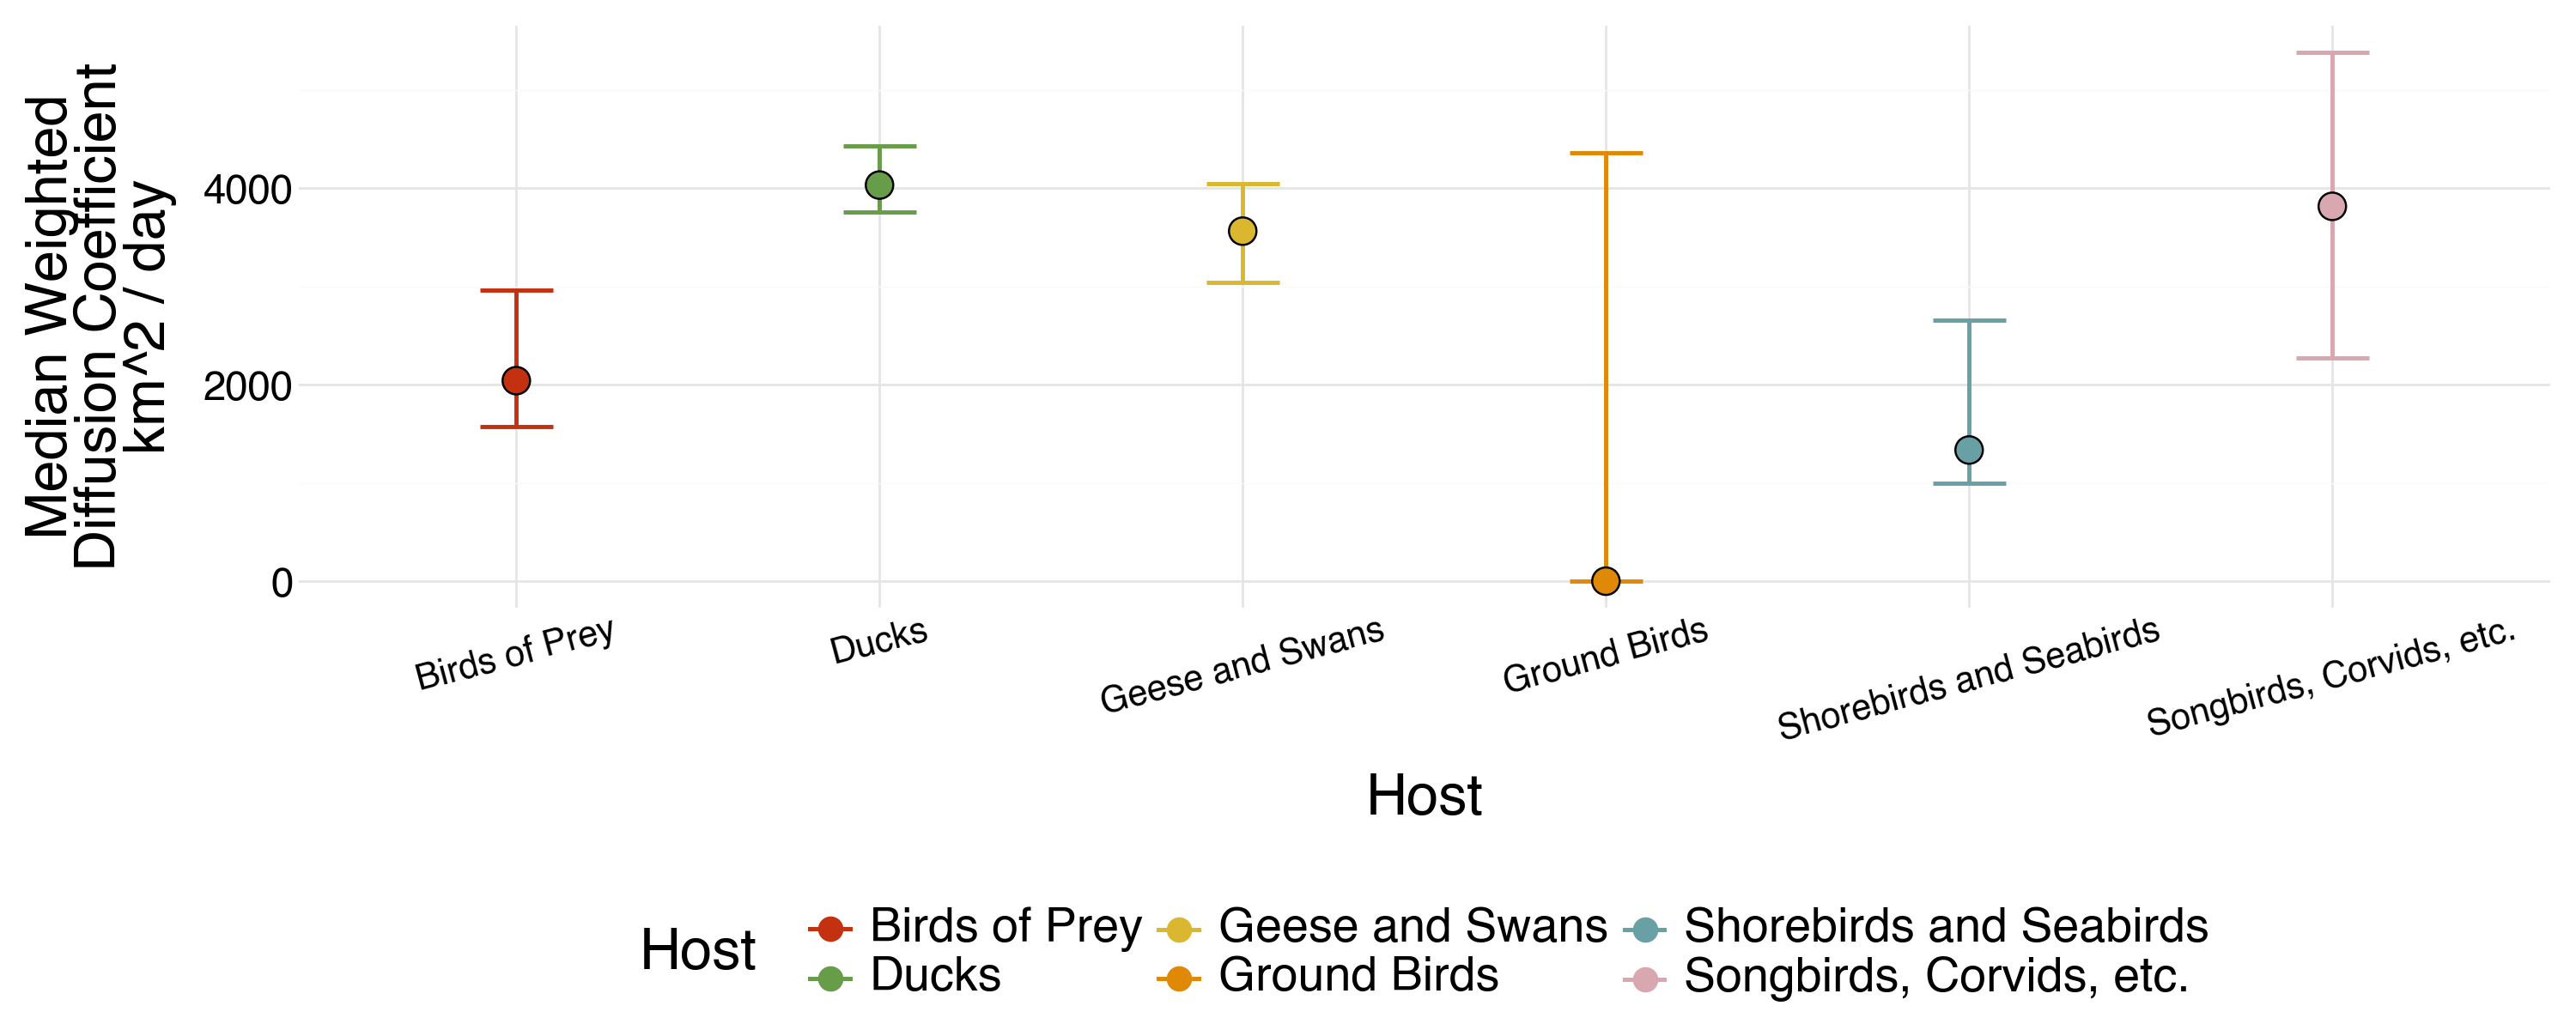

In [30]:
plt1A = (
    ggplot()
    + geom_errorbar(host_hpd_posterior_wdc, aes(x = "trait", ymin = "lower", ymax = "upper", color = "trait"), width = 0.2, size = 1)
    + geom_point(host_hpd_posterior_wdc, aes(x = "trait", y = "median"), size = 6, color = "black")
    + geom_point(host_hpd_posterior_wdc, aes(x = "trait", y = "median", color = "trait"), size = 5)
    + labs(x = "Host", y = "Median Weighted\nDiffusion Coefficient\nkm^2 / day", color = "Host")
    + scale_color_manual(values = host_colors, labels = host_labels)
    + scale_x_discrete(labels = host_labels)
    # + ylim(-1, 5000)
    + theme_minimal()
    + theme(figure_size = (15,6), 
            legend_title = element_text(size = 24), legend_text=element_text(size=20), legend_position = "bottom", legend_direction = "horizontal",
            axis_title_x = element_text(size = 24), axis_text_y = element_text(size = 17, color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 15, rotation = 15, color = "black"))
)

plt1A.show()

In [31]:
def decimal_year_to_datetime(decimal_year):
    year = int(decimal_year)
    remainder = decimal_year - year

    start = datetime(year, 1, 1)
    end = datetime(year + 1, 1, 1)

    return (start + timedelta(seconds=remainder * (end - start).total_seconds())).date()

In [32]:
def extract_month_index(dictionary):

    date_list = []

    for i in dictionary.values():
        i["startYear_datetime"] = i["startYear"].apply(decimal_year_to_datetime) # Turn startYear from a float into a datetime object
        i["endYear_datetime"] = i["endYear"].apply(decimal_year_to_datetime) # Turn endYear from a float into a datetime object
        start = min(i["startYear_datetime"])
        end = max(i["endYear_datetime"])
        months = pd.date_range(start = start, end = end, freq = "MS")
        for month in months:
            month_date = month.date()
            if month_date in date_list:
                pass
            else:
                date_list.append(month_date)

    date_list_sorted = sorted(date_list)

    return(date_list_sorted)

In [63]:
# Function: calculates WDC over time

def calculate_monthly_wdc(metadata, TRAIT, trait_list, PROB):
         
    posterior_wdc_dict = {} # Initialize the dictionary for all hosts
    
    date_list = extract_month_index(metadata) # This provides a list of month start dates across the entire posterior

    hdi_traits = [] # Initialize a list for HPD for all traits to use later

    for trait in trait_list: # Can change this depending on the traits

        count = 1 # Start counting dataframes

        posterior_wdc_dict[trait] = {} # Make an entry per host
        
        trait_dfs = [] # Make a list for all the dataframes

        for df in metadata.values(): # Iterate over each dataframe

            wdc_per_df = {} # Initialize a dictionary for EACH TREE/DATAFRAME
        
            df["startYear_datetime"] = df["startYear"].apply(decimal_year_to_datetime) # Turn startYear from a float into a datetime object
            df["endYear_datetime"] = df["endYear"].apply(decimal_year_to_datetime) # Turn endYear from a float into a datetime object
        
            mask1 = ((df[f"start{TRAIT}"] == trait) & (df[f"end{TRAIT}"] == trait)) # Limit to just the trait in question (calculate WDC just within that trait)
            df_trait = df[mask1]
    
            for month in date_list: # For each month of the dataframe
                wdc_per_df[month] = {} # Entry in dictionary per month
                
                mask2 = ((df_trait["startYear_datetime"] <= month) & (df_trait["endYear_datetime"] > month)) # all branches that start before or at the month start and end after the month start
                trait_monthly_branches = df_trait[mask2]
                
                if len(trait_monthly_branches) == 0: # Some months have 0 branches, which generates a NaN wonthly_wdc because you cannot divide by time
                    monthly_wdc = 0
                else:
                    monthly_wdc = (trait_monthly_branches["dist_branch"] ** 2).sum() / (4 * (trait_monthly_branches["time"] * 365)).sum() # Calculate WDC per month with time in days, not years
               
                wdc_per_df[month] = monthly_wdc
    
            wdc_df = pd.DataFrame.from_dict(wdc_per_df, orient = "index").reset_index()
            wdc_df.columns = ["month", f"tree{count}_monthlywdc"]
            wdc_df[f"{TRAIT}"] = trait

            trait_dfs.append(wdc_df) # Save each dataframe to a different list for each trait
        
            count += 1
    
        per_trait_posterior = pd.concat((df.set_index(["month", f"{TRAIT}"]) for df in trait_dfs), axis = 1) # Concatenate all the dataframes within each list (within each trait)
        
        posterior_wdc_dict[trait] = per_trait_posterior
        
    for i in posterior_wdc_dict.values():
        
        hdi_rows = i.apply(lambda row: az.hdi(row.values, hdi_prob = PROB), axis=1)
        hdi_series = hdi_rows.apply(pd.Series)
        hdi_series.columns = ["lower", "upper"]

        hdi_series["median"] = i.median(axis = 1)

        # This chunk is a way of limiting our analysis to show only the WDC over time for certain hosts
        # consecutive_median_zero = hdi_series.loc[hdi_series["median"] == 0].cumcount()
        consecutive_median_zero = (hdi_series["median"] == 0).groupby((hdi_series["median"] != 0).cumsum()).cumsum() # ChatGPT helped adjust the code above to do the right thing
        if consecutive_median_zero.max() > 24: # only consider hosts if there is over 2 years of NO median spread
            # print(hdi_series["median"])
            pass
        else:
            hdi_traits.append(hdi_series)

        # print(hdi_series)

    all_hdi_traits = pd.concat(hdi_traits).reset_index()
    # concatenated_reindexed = concatenated.reset_index()
    # print(concatenated_reindexed)

    return(posterior_wdc_dict, all_hdi_traits)

In [64]:
# host_trait_list = ["duck", "shorebird", "bird-of-prey", "goose-swan", "songbird-etc"]
host_trait_list = ["duck", "shorebird", "bird-of-prey", "goose-swan", "songbird-etc", "ground-bird", "diving-bird", "other"]

host_overtime_wdc, host_hdi_overtime_wdc = calculate_monthly_wdc(metadata_dict, "Host", host_trait_list, 0.95)

In [89]:
# def select_date_labels(df, date_column):
#     df[date_column] = pd.to_datetime(df[date_column])
#     all_dates = df[date_column]
#     date_labels = [d.strftime("%Y-%m") if d.month in [3, 6, 9, 12] else "" for d in all_dates]
#     return(all_dates, date_labels)

In [65]:
host_hdi_overtime_wdc["month"] = pd.to_datetime(host_hdi_overtime_wdc["month"])

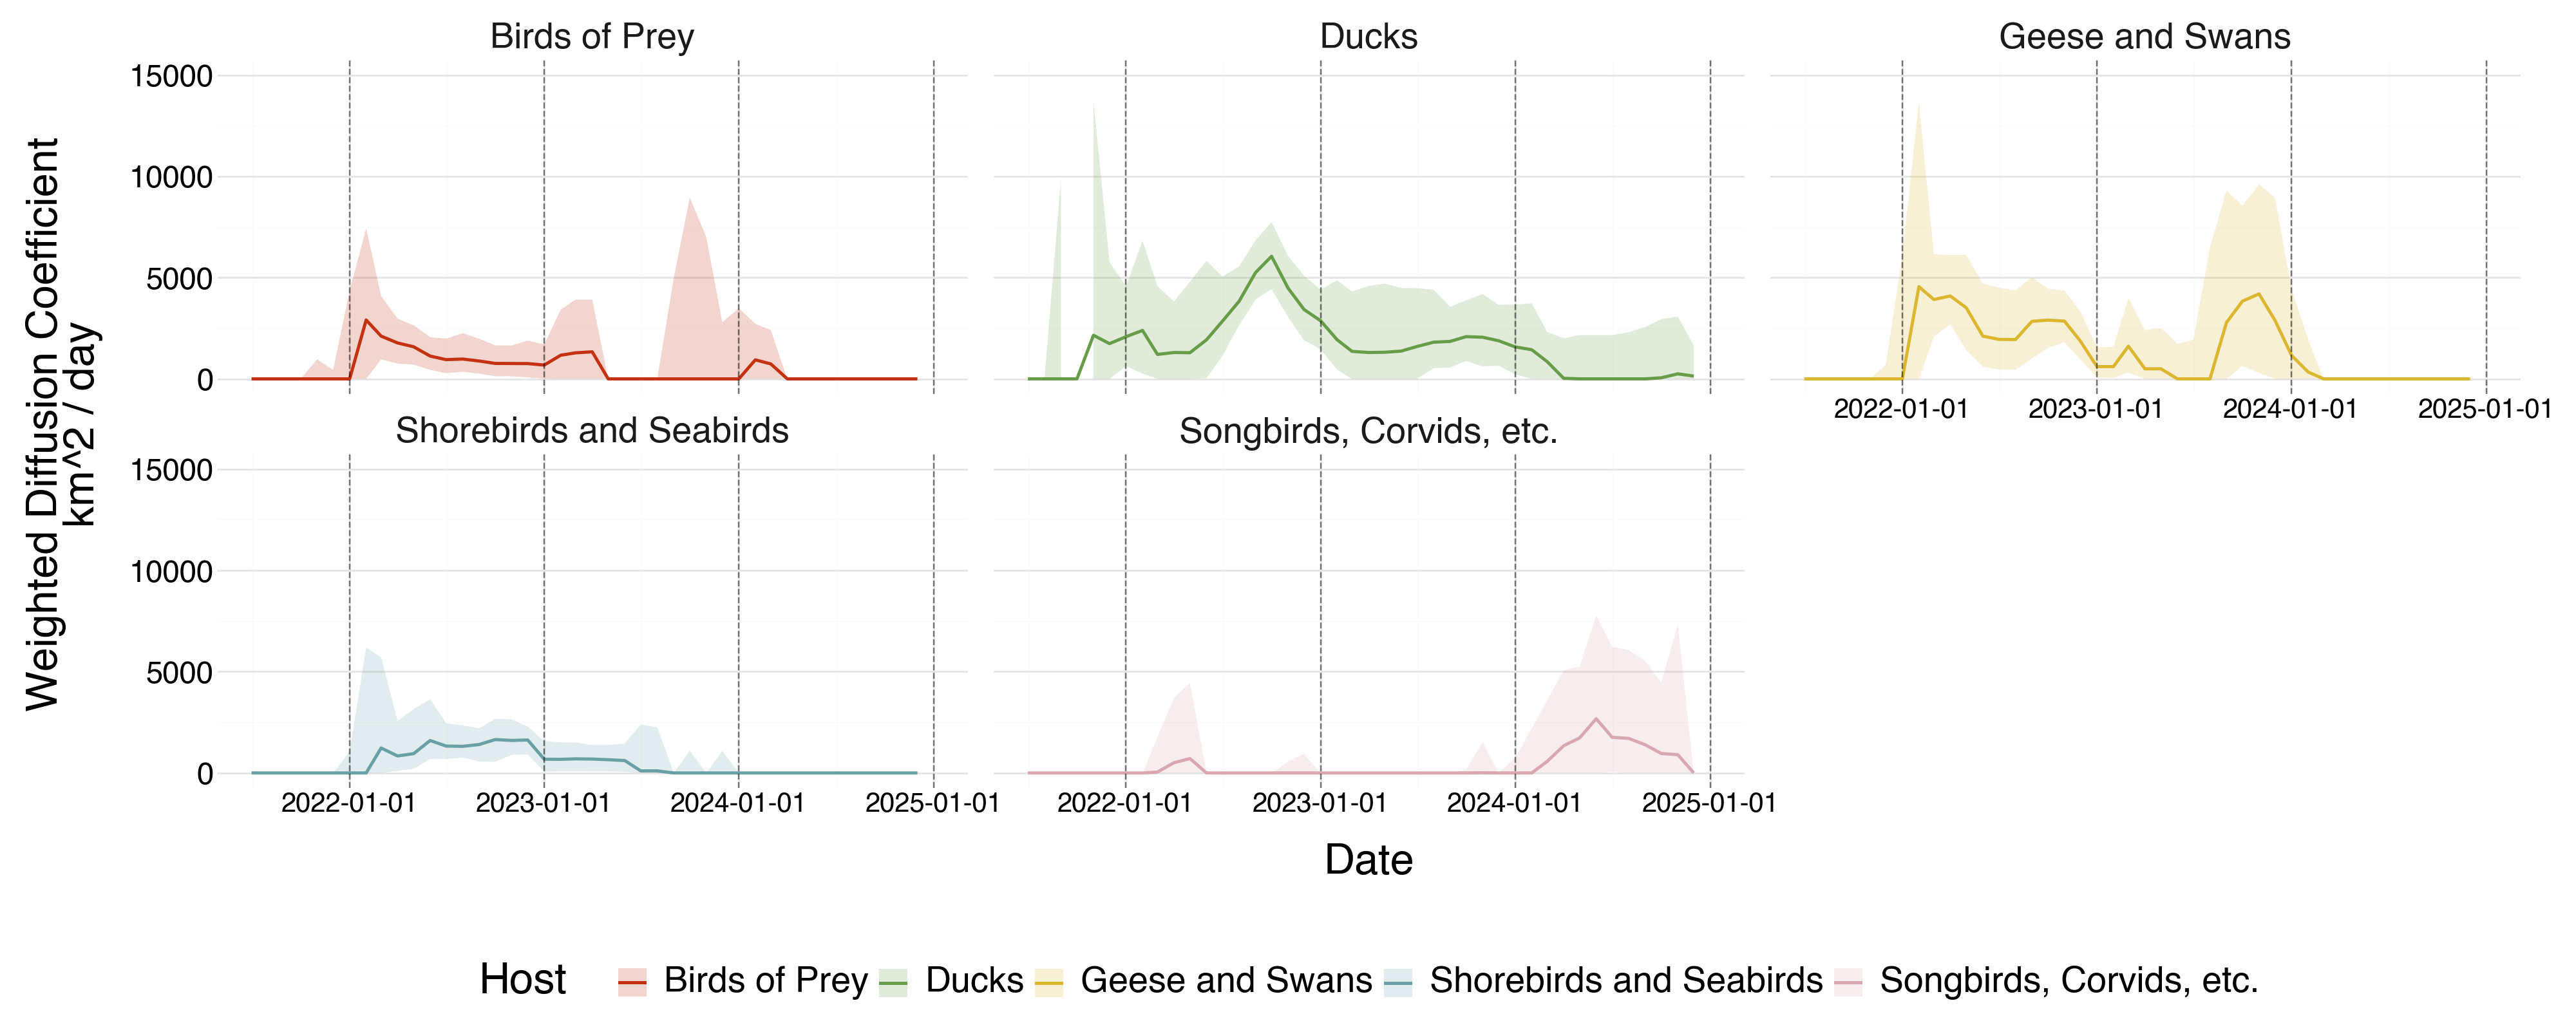

In [68]:
plt2A = (
    ggplot(host_hdi_overtime_wdc)
    + geom_ribbon(aes(x = "month", ymin = "lower", ymax = "upper", fill = "Host", group = "Host"), color = None, alpha = 0.2)
    + geom_line(aes(x = "month", y = "median", color = "Host", group = "Host"), size = 1)
    + facet_wrap("Host", labeller = host_labels)
    + labs(x = "Date", y = "Weighted Diffusion Coefficient\nkm^2 / day", color = "Host", fill = "Host")
    + scale_color_manual(host_colors, labels = host_labels)
    + scale_fill_manual(host_colors, labels = host_labels)
    + geom_vline(xintercept = ["2022-01-01", "2023-01-01", "2024-01-01", "2025-01-01"], linetype = "dashed", size = 0.5, alpha = 0.5)
    + ylim(-1, 15000)
    + theme_minimal()
    + theme(figure_size = (20,8), text=element_text(size=20), 
            legend_title = element_text(size = 24), legend_text=element_text(size=20), legend_position = "bottom", legend_direction = "horizontal",
            axis_title_x = element_text(size = 24), axis_text_y = element_text(size = 17, color = "black"),
            axis_title_y = element_text(size = 24), axis_text_x = element_text(size = 15, color = "black"))
)

plt2A.show()

In [92]:
# DIRECTORY = "live-harvest"
# DIRECTORY = "equal-time-location"
# DIRECTORY = "equal-time-host-3000"
# DIRECTORY = "equal-time-host-1000"
# DIRECTORY = "proportional-time-host"
DIRECTORY = "proportional-time-location"

In [93]:
plt1A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/wdc_overall_{DIRECTORY}_host.png", format = "png", dpi = 750)
plt1A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/wdc_overall_{DIRECTORY}_host.pdf", format = "pdf", dpi = 750)
# plt1B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/wdc_overall_{DIRECTORY}_flyway.png", format = "png", dpi = 750)
# plt1B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/wdc_overall_{DIRECTORY}_flyway.pdf", format = "pdf", dpi = 750)
plt2A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/wdc_overtime_{DIRECTORY}_host.png", format = "png", dpi = 750)
plt2A.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/wdc_overtime_{DIRECTORY}_host.pdf", format = "pdf", dpi = 750)
# plt2B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/wdc_overtime_{DIRECTORY}_flyway.png", format = "png", dpi = 750)
# plt2B.save(f"./analyses/main-intro_six-datasets_mjr/{DIRECTORY}/wdc_overtime_{DIRECTORY}_flyway.pdf", format = "pdf", dpi = 750)

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./analyses/main-intro_six-datasets_mjr/proportional-time-location/wdc_overall_proportional-time-location_host.png
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./analyses/main-intro_six-datasets_mjr/proportional-time-location/wdc_overall_proportional-time-location_host.pdf
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: Plotnin